In [1]:
import pandas as pd
# from google.colab import drive
# drive.mount('/content/drive')

In [4]:
data_path_pre = '../ronaldo-top/ronaldo-top_preprocessed.csv'
data = pd.read_csv(data_path_pre)
data.shape

(564, 16)

In [5]:
data.head(1)

,conversation_id_str,created_at,favorite_count,id_str,image_url,in_reply_to_screen_name,lang,location,quote_count,reply_count,retweet_count,tweet_url,user_id_str,username,text_original,text_clean
0,2106927418057310298,2026-10-05T02:00:15.000Z,4690,2106927418057310298,https://pbs.twimg.com/amplify_video_thumb/2106...,NaN,en,NaN,120,258,804,https://x.com/afc_Ade1/status/2106927418057310298,2080781657766805505,afc_Ade1,Ronaldo needs to find a way to get this video ...,Ronaldo needs to find a way to get this video ...


In [11]:
data[["conversation_id_str", "created_at", "favorite_count", "text_original", "text_clean"]].head(8)

,conversation_id_str,created_at,favorite_count,text_original,text_clean
0,2106927418057310298,2026-10-05T02:00:15.000Z,4690,Ronaldo needs to find a way to get this video ...,Ronaldo needs to find a way to get this video ...
1,2107388414811361592,2026-10-06T08:32:06.000Z,2916,One player doesn’t make a team but 75% of the ...,One player doesn’t make a team but 75% of the ...
2,2107179851425649058,2026-10-05T18:43:20.000Z,1861,"If you like, let anyone whine you about Ronald...","If you like, let anyone whine you about Ronald..."
3,2107837996003402032,2026-10-07T14:18:34.000Z,1470,"Cristiano Ronaldo: ""Please be nice about me Jo...","Cristiano Ronaldo: ""Please be nice about me Jo..."
4,2107805832868245890,2026-10-07T12:10:46.000Z,367,Cristiano Ronaldo - Goal Catalogue\n\n[@Cristi...,Cristiano Ronaldo - Goal Catalogue [@Cristiano...
5,2106078375164907767,2026-10-02T17:46:28.000Z,6515,Ronaldo really went on to protest after he tri...,Ronaldo really went on to protest after he tri...
6,2107772425693765781,2026-10-07T09:58:01.000Z,678,Messi doesn’t even play in Saudi Arabia and st...,Messi doesn’t even play in Saudi Arabia and st...
7,2107806687046549563,2026-10-07T12:14:10.000Z,351,"Remove the World cup Messi won over Ronaldo, t...","Remove the World cup Messi won over Ronaldo, t..."


In [9]:
data_path_sentiment = '../sentimen/ronaldo_labeled.csv'
data_label = pd.read_csv(data_path_sentiment)
data_label.shape

(565, 3)

In [10]:
data_label.head(1)

,text_clean,sentimen,confidence
0,as my final act of love for ronaldo i will bec...,Positive,0.835588


In [12]:
pd.to_datetime(data['created_at']).dt.hour.head(5)

0     2
1     8
2    18
3    14
4    12
Name: created_at, dtype: int32

In [46]:
data['posting_hour'] = data['text_clean'].str.split().str.len()
data['has_image'] = data['image_url'].notna().astype(int)
data['text_length'] = data['text_clean'].fillna('').astype(str).str.len()
data['word_count'] = data['text_clean'].fillna('').astype(str).str.split().str.len()

In [47]:
data['sentiment_code'] = data_label['sentimen'].astype('category').cat.codes
data

,conversation_id_str,created_at,favorite_count,id_str,image_url,in_reply_to_screen_name,lang,location,quote_count,reply_count,...,tweet_url,user_id_str,username,text_original,text_clean,posting_hour,has_image,text_length,word_count,sentiment_code
0,2106927418057310298,2026-10-05T02:00:15.000Z,4690,2106927418057310298,https://pbs.twimg.com/amplify_video_thumb/2106...,NaN,en,NaN,120,258,...,https://x.com/afc_Ade1/status/2106927418057310298,2080781657766805505,afc_Ade1,Ronaldo needs to find a way to get this video ...,Ronaldo needs to find a way to get this video ...,27,1,123,27,2
1,2107388414811361592,2026-10-06T08:32:06.000Z,2916,2107388414811361592,https://pbs.twimg.com/amplify_video_thumb/2107...,NaN,en,NaN,39,97,...,https://x.com/ChessLordK/status/21073884148113...,1612844910369030145,ChessLordK,One player doesn’t make a team but 75% of the ...,One player doesn’t make a team but 75% of the ...,27,1,149,27,0
2,2107179851425649058,2026-10-05T18:43:20.000Z,1861,2107179851425649058,https://pbs.twimg.com/amplify_video_thumb/2107...,NaN,en,NaN,51,125,...,https://x.com/buzor042_/status/210717985142564...,1561968071547420674,buzor042_,"If you like, let anyone whine you about Ronald...","If you like, let anyone whine you about Ronald...",23,1,129,23,1
3,2107837996003402032,2026-10-07T14:18:34.000Z,1470,2107837996003402032,https://pbs.twimg.com/amplify_video_thumb/2107...,NaN,en,NaN,52,36,...,https://x.com/FootballRamble/status/2107837996...,19393128,FootballRamble,"Cristiano Ronaldo: ""Please be nice about me Jo...","Cristiano Ronaldo: ""Please be nice about me Jo...",12,1,75,12,2
4,2107805832868245890,2026-10-07T12:10:46.000Z,367,2107805832868245890,https://pbs.twimg.com/amplify_video_thumb/1997...,NaN,en,NaN,2,7,...,https://x.com/MohUtd_/status/2107805832868245890,1662475776711618560,MohUtd_,Cristiano Ronaldo - Goal Catalogue\n\n[@Cristi...,Cristiano Ronaldo - Goal Catalogue [@Cristiano...,8,1,58,8,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
559,2107353663396069630,2026-10-06T06:14:00.000Z,244,2107353663396069630,https://pbs.twimg.com/amplify_video_thumb/2107...,NaN,en,NaN,4,72,...,https://x.com/ELLIOTTTTFC/status/2107353663396...,1268931516844740619,ELLIOTTTTFC,🚨EXCL: Cristiano Ronaldo opens up why he wants...,EXCL: Cristiano Ronaldo opens up why he wants ...,47,1,264,47,0
560,2108023082099396682,2026-10-08T02:34:02.000Z,0,2108023082099396682,NaN,NaN,en,NaN,0,0,...,https://x.com/unmessy_22/status/21080230820993...,1263507756679483392,unmessy_22,"messi , maradona, pele sitting at the same tab...","messi , maradona, pele sitting at the same tab...",30,0,163,30,0
561,2107757291571232793,2026-10-07T08:57:53.000Z,1170,2107757291571232793,NaN,NaN,en,NaN,16,41,...,https://x.com/RayToluAyo/status/21077572915712...,315834089,RayToluAyo,Out of everything Cristiano Ronaldo said in hi...,Out of everything Cristiano Ronaldo said in hi...,50,0,274,50,1
562,2107951551381643467,2026-10-07T21:49:48.000Z,0,2107951551381643467,NaN,NaN,en,NaN,0,1,...,https://x.com/adekunleyshittu/status/210795155...,265015639,adekunleyshittu,"Ronaldo has endured criticism, setbacks and di...","Ronaldo has endured criticism, setbacks and di...",39,0,246,39,0


In [48]:
kolom_pilihan = [
    'favorite_count',
    'retweet_count',
    'reply_count',
    'quote_count',
    'text_length',
    'word_count',
    'posting_hour',
    'has_image',
    'sentiment_code'
]

df_fitur = data[kolom_pilihan].copy()

df_fitur.to_csv('data_regresi_twitter.csv', index=False)

print("File 'data_regresi_twitter.csv'")
print(df_fitur.head(3))

File 'data_regresi_twitter.csv'
   favorite_count  retweet_count  reply_count  quote_count  text_length  \
0            4690            804          258          120          123   
1            2916            682           97           39          149   
2            1861            335          125           51          129   

   word_count  posting_hour  has_image  sentiment_code  
0          27            27          1               2  
1          27            27          1               0  
2          23            23          1               1  


In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

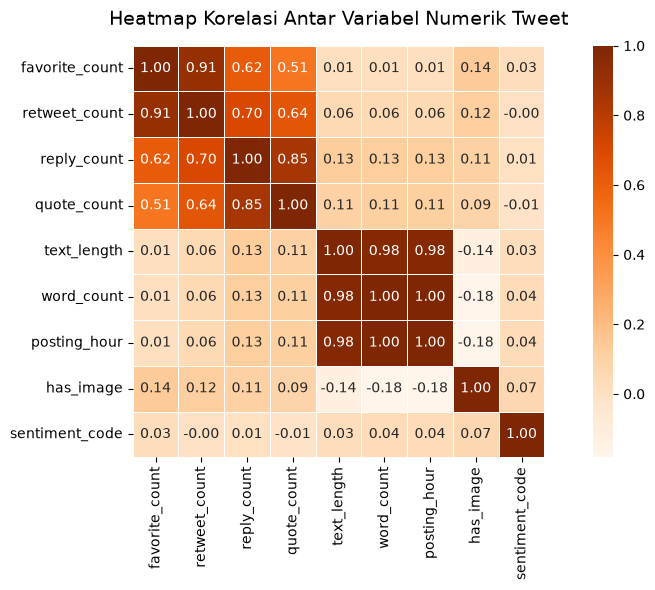

In [ ]:
matriks_korelasi = df_fitur.corr(method='pearson')

plt.figure(figsize=(10, 6))
sns.heatmap(
    matriks_korelasi,
    annot=True,
    cmap='Oranges',
    fmt='.2f',
    linewidths=0.5,
    square=True
)

plt.title('Heatmap Korelasi Antar Variabel Numerik Tweet', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

In [50]:
import numpy as np

threshold = 0.80

sol = matriks_korelasi.where(np.triu(np.ones(matriks_korelasi.shape), k=1).astype(bool))

pasangan_korelasi = sol.unstack().dropna()
data_pasangan = pasangan_korelasi.reset_index()
data_pasangan.columns = ['Variabel_1', 'Variabel_2', 'Nilai_Korelasi']
data_pasangan['Korelasi_Absolut'] = df_pasangan['Nilai_Korelasi'].abs()

df_terurut = df_pasangan.sort_values(by='Korelasi_Absolut', ascending=False).drop(columns=['Korelasi_Absolut'])

multikolinearitas = df_terurut[df_terurut['Nilai_Korelasi'].abs() >= threshold]

print("Pasangan Variabel Terurut Berdasarkan Korelasi Tertinggi")
print(df_terurut.to_string(index=False))

print(f"\nPasangan Variabel Terindikasi Multikolinearitas (|r| >= {threshold})")
print(multikolinearitas.to_string(index=False))

Pasangan Variabel Terurut Berdasarkan Korelasi Tertinggi
    Variabel_1     Variabel_2  Nilai_Korelasi
  posting_hour     word_count        1.000000
  posting_hour    text_length        0.981320
    word_count    text_length        0.981320
 retweet_count favorite_count        0.910897
   quote_count    reply_count        0.850297
   reply_count  retweet_count        0.704944
   quote_count  retweet_count        0.642424
   reply_count favorite_count        0.618243
   quote_count favorite_count        0.509929
     has_image   posting_hour       -0.182146
     has_image     word_count       -0.182146
     has_image favorite_count        0.140344
     has_image    text_length       -0.135704
   text_length    reply_count        0.130868
    word_count    reply_count        0.126128
  posting_hour    reply_count        0.126128
     has_image  retweet_count        0.121967
  posting_hour    quote_count        0.113695
    word_count    quote_count        0.113695
   text_length    quote

In [52]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = data[['posting_hour','text_length','favorite_count',
        'reply_count','quote_count','has_image','sentiment_code']]
X = sm.add_constant(X)

vif = pd.DataFrame({
    'Variabel': X.columns,
    'VIF': [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
})
print(vif)

         Variabel        VIF
0           const   1.000000
1    posting_hour  29.317747
2     text_length  28.860117
3  favorite_count   1.647751
4     reply_count   4.404223
5     quote_count   3.652520
6       has_image   1.125609
7  sentiment_code   1.011911


In [54]:
y = data['retweet_count']

data = pd.concat([X, y], axis=1).replace([np.inf, -np.inf], np.nan).dropna()
X = sm.add_constant(data.drop(columns='retweet_count').astype(float))
y = data['retweet_count'].astype(float)

model = sm.OLS(y, X).fit()
print(model.summary())

resid = model.resid
fitted = model.fittedvalues

                            OLS Regression Results                            
Dep. Variable:          retweet_count   R-squared:                       0.874
Model:                            OLS   Adj. R-squared:                  0.872
Method:                 Least Squares   F-statistic:                     551.3
Date:                Wed, 14 Oct 2026   Prob (F-statistic):          1.95e-245
Time:                        17:59:14   Log-Likelihood:                -4220.9
No. Observations:                 564   AIC:                             8458.
Df Residuals:                     556   BIC:                             8492.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const             64.8603     52.091      1.

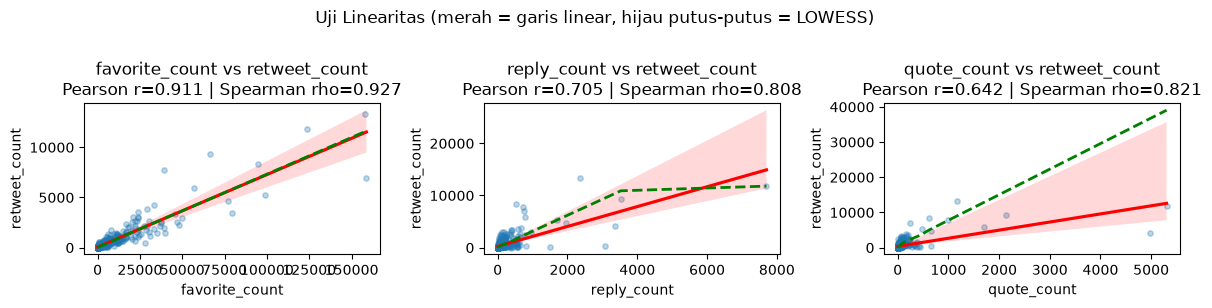

         Variabel  Pearson_r  p_Pearson  Spearman_rho  p_Spearman
0  favorite_count     0.9109        0.0        0.9266         0.0
1     reply_count     0.7049        0.0        0.8081         0.0
2     quote_count     0.6424        0.0        0.8206         0.0


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.nonparametric.smoothers_lowess import lowess

y = 'retweet_count'
num_vars = ['favorite_count', 'reply_count', 'quote_count']

data = data[num_vars + [y]].replace([np.inf, -np.inf], np.nan).dropna()

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
axes = axes.flatten()

hasil = []
for ax, var in zip(axes, num_vars):
    # scatter + garis linear (merah)
    sns.regplot(x=data[var], y=data[y], ax=ax,
                scatter_kws={'alpha': 0.3, 's': 15},
                line_kws={'color': 'red'})

    # garis LOWESS (hijau putus-putus), dihitung manual
    smooth = lowess(data[y], data[var], frac=0.3)
    ax.plot(smooth[:, 0], smooth[:, 1], color='green', linestyle='--', linewidth=2)

    r, p = stats.pearsonr(data[var], data[y])
    rho, p_s = stats.spearmanr(data[var], data[y])
    ax.set_title(f'{var} vs {y}\nPearson r={r:.3f} | Spearman rho={rho:.3f}')
    hasil.append([var, r, p, rho, p_s])

plt.suptitle('Uji Linearitas (merah = garis linear, hijau putus-putus = LOWESS)', y=1.01)
plt.tight_layout()
plt.show()

print(pd.DataFrame(hasil, columns=['Variabel', 'Pearson_r', 'p_Pearson',
                                   'Spearman_rho', 'p_Spearman']).round(4))

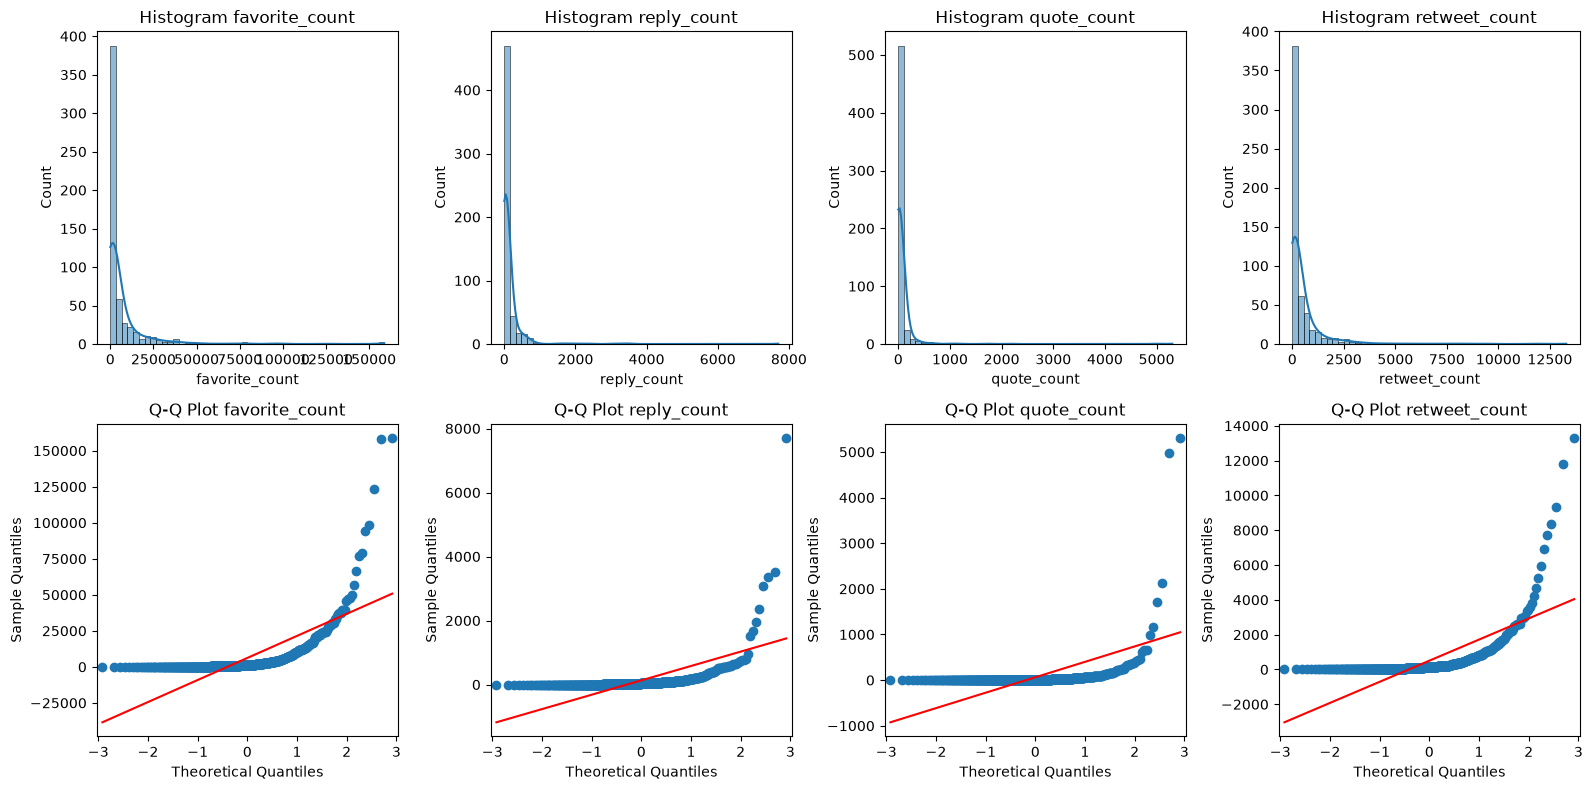

         Variabel  Lilliefors_stat  p_value  Skewness  Kurtosis
0  favorite_count           0.3434    0.001    5.9094   45.3681
1     reply_count           0.3843    0.001   10.9437  156.0832
2     quote_count           0.4270    0.001   12.7713  181.8265
3   retweet_count           0.3392    0.001    5.9820   46.1294


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats

num_vars = ['favorite_count', 'reply_count', 'quote_count', 'retweet_count']
data = data[num_vars].replace([np.inf, -np.inf], np.nan).dropna()

fig, axes = plt.subplots(2, len(num_vars), figsize=(4 * len(num_vars), 8))

hasil = []
for i, var in enumerate(num_vars):
    sns.histplot(data[var], kde=True, ax=axes[0, i])
    axes[0, i].set_title(f'Histogram {var}')
    sm.qqplot(data[var], line='s', ax=axes[1, i])
    axes[1, i].set_title(f'Q-Q Plot {var}')

    from statsmodels.stats.diagnostic import lilliefors
    ks_stat, ks_p = lilliefors(data[var], dist='norm')
    skew, kurt = stats.skew(data[var]), stats.kurtosis(data[var])
    hasil.append([var, ks_stat, ks_p, skew, kurt])

plt.tight_layout()
plt.show()

print(pd.DataFrame(hasil, columns=['Variabel', 'Lilliefors_stat', 'p_value',
                                   'Skewness', 'Kurtosis']).round(4))

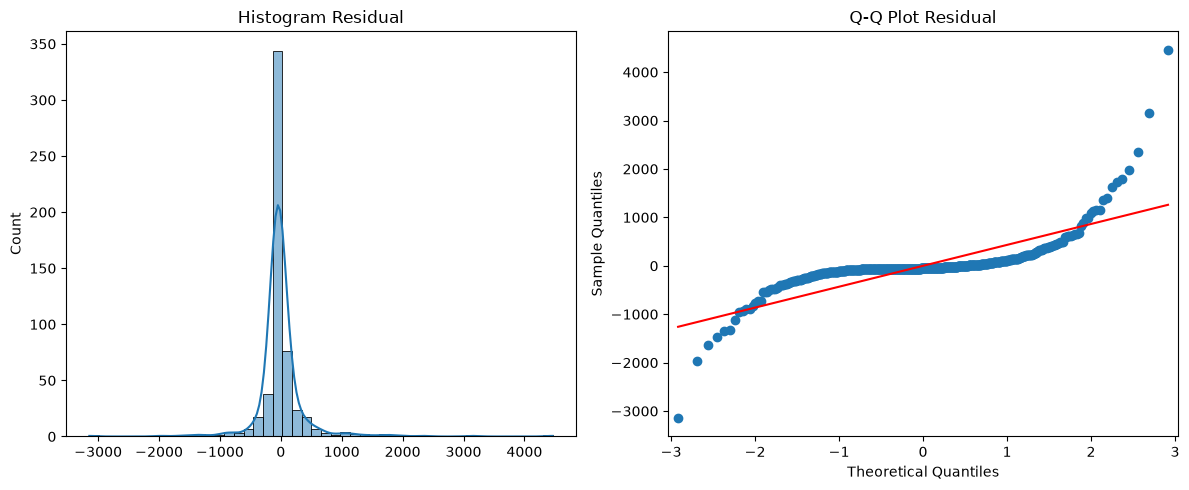

Lilliefors residual: (np.float64(0.2497905478704172), np.float64(0.0009999999999998899))
Jarque-Bera residual: SignificanceResult(statistic=np.float64(27529.181602465887), pvalue=np.float64(0.0))


In [67]:
X = sm.add_constant(data[['favorite_count', 'reply_count', 'quote_count']])
model = sm.OLS(data['retweet_count'], X).fit()
resid = model.resid

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(resid, kde=True, ax=axes[0])
axes[0].set_title('Histogram Residual')
sm.qqplot(resid, line='s', ax=axes[1])
axes[1].set_title('Q-Q Plot Residual')
plt.tight_layout()
plt.show()

from statsmodels.stats.diagnostic import lilliefors
print('Lilliefors residual:', lilliefors(resid, dist='norm'))
print('Jarque-Bera residual:', stats.jarque_bera(resid))

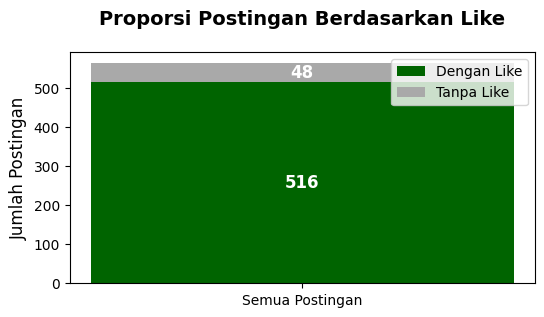

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

data['retweet_count_log'] = np.log1p(data['retweet_count'])
data['favorite_count_log'] = np.log1p(data['favorite_count'])
data['reply_count_log']    = np.log1p(data['reply_count'])
data['quote_count_log']    = np.log1p(data['quote_count'])

X = data[['favorite_count_log', 'reply_count_log', 'quote_count_log',
        'text_length', 'has_image', 'sentiment_code']]
X = sm.add_constant(X.astype(float))
y = df['retweet_count_log']

model = sm.OLS(y, X).fit(cov_type='HC3')   # error standar robust
print(model.summary())

In [ ]:
import pandas as pd
import re
from collections import Counter

data['list_tagar'] = data['text_clean'].apply(lambda x: re.findall(r'#\w+', str(x)))
data['jumlah_tagar'] = data['list_tagar'].apply(len)

In [ ]:
pakai_tagar = (data['reply_count'] > 0).sum()
tanpa_tagar = (data['reply_count'] == 0).sum()

print(f"Ada repluy : {pakai_tagar} ({pakai_tagar/total_postingan*100:.1f}%)")
print(f"Tidak ada reply : {tanpa_tagar} ({tanpa_tagar/total_postingan*100:.1f}%)")
print(f"Total: {total_postingan}")

Ada repluy : 478 (84.8%)
Tidak ada reply : 86 (15.2%)
Total: 564


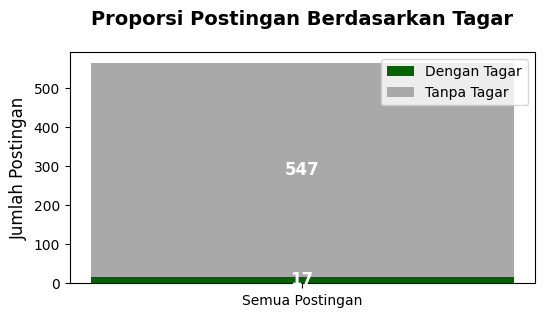

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 3))

p1 = plt.bar('Semua Postingan', pakai_tagar, color='darkgreen', width=0.25, label='Dengan Tagar')
p2 = plt.bar('Semua Postingan', tanpa_tagar, bottom=pakai_tagar, color='darkgrey', width=0.25, label='Tanpa Tagar')

plt.text(0, pakai_tagar / 2, f"{pakai_tagar:,}",
         ha='center', va='center', color='white', fontweight='bold', fontsize=12)

plt.text(0, pakai_tagar + (tanpa_tagar / 2), f"{tanpa_tagar:,}",
         ha='center', va='center', color='white', fontweight='bold', fontsize=12)

plt.title('Proporsi Postingan Berdasarkan Tagar', fontsize=14, fontweight='bold', pad=20)
plt.ylabel('Jumlah Postingan', fontsize=12)
plt.legend(loc='upper right')

plt.show()

In [ ]:
dataset_bertagar = data[data['jumlah_tagar'] > 0]
distribusi_tagar = dataset_bertagar['jumlah_tagar'].value_counts().sort_index()

print("Distribusi")
for jml, total in distribusi_tagar.items():
    print(f"{jml} tagar : {total} post")

Distribusi
1 tagar : 2 post
2 tagar : 5 post
3 tagar : 5 post
4 tagar : 2 post
5 tagar : 3 post


In [ ]:
semua_tagar = [tagar.lower() for sublist in data['list_tagar'] for tagar in sublist]

frekuensi_tagar = Counter(semua_tagar)

print(f"Total tagar unik yang ditemukan: {len(frekuensi_tagar)} tagar\n")

print("Top 10 Tagar")
for tagar, count in frekuensi_tagar.most_common(10):
    print(f"{tagar:<20} : {count} kali")

print(f"List tagar unik:{list(frekuensi_tagar.keys())}")

Total tagar unik yang ditemukan: 29 tagar

Top 10 Tagar
#ronaldo             : 11 kali
#portugal            : 5 kali
#messi               : 4 kali
#cr7                 : 2 kali
#jorgejesus          : 2 kali
#lionelmessi         : 2 kali
#argentina           : 2 kali
#uefa                : 1 kali
#ucl                 : 1 kali
#cristiano           : 1 kali
List tagar unik:['#uefa', '#ucl', '#cristiano', '#cr7', '#cristianoronaldo', '#ronaldo', '#portugal', '#jorgejesus', '#portugalnt', '#bbcfootball', '#euroleagues', '#lionelmessi', '#messiretirement', '#ronaldoretirement', '#orange1079', '#messi', '#orangesports', '#sick', '#thesidseixeiroshow', '#argentina', '#messilastmatch', '#maradona', '#soccer', '#nufc', '#lufc', '#lfc', '#sportyfm', '#omahlay', '#tram']


In [ ]:
# 1. Pilih kolom-kolom target (like, reply, retweet)
dataset_hasil = data[['favorite_count', 'reply_count', 'retweet_count']].copy()

# 2. Hapus baris yang memiliki nilai kosong (NaN) pada ketiga kolom tersebut
dataset_hasil = dataset_hasil.dropna(subset=['favorite_count', 'reply_count', 'retweet_count'])

# 3. Ubah nama kolom sesuai permintaan (like, reply, retweet)
dataset_hasil = dataset_hasil.rename(columns={
    'favorite_count': 'like',
    'reply_count': 'reply',
    'retweet_count': 'retweet'
})

# 4. Simpan ke file CSV terpisah
dataset_hasil.to_csv('dataset_engagement_metrics.csv', index=False)

print("File 'dataset_engagement_metrics.csv' berhasil disimpan!")
print(dataset_hasil.head())

File 'dataset_engagement_metrics.csv' berhasil disimpan!
   like  reply  retweet
0  4690    258      804
1  2916     97      682
2  1861    125      335
3  1470     36      323
4   367      7       64


In [ ]:
cek_data = pd.read_csv("dataset_engagement_metrics.csv")
cek_data.head(2)

,like,reply,retweet
0,4690,258,804
1,2916,97,682


# Regresi

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

In [ ]:
dataset = pd.read_csv('dataset_engagement_metrics.csv')
dataset

,like,reply,retweet
0,4690,258,804
1,2916,97,682
2,1861,125,335
3,1470,36,323
4,367,7,64
...,...,...,...
559,244,72,202
560,0,0,0
561,1170,41,284
562,0,1,0


In [ ]:
import pandas as pd

X = dataset[['like', 'reply']]
y = dataset['retweet']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

b0 = model.intercept_
b1 = model.coef_[0]
b2 = model.coef_[1]

In [ ]:
print(f"Jumlah Like = {b0:.2f} + ({b1:.2f} * Jumlah Kata) + ({b2:.2f} * Jumlah Tagar)")

print(f"Intersep \t\t\t: {b0:.2f}")
print(f"Jumlah kata (X1)\t\t: {b1:.2f}")
print(f"Jumlah Tagar (X2)\t\t: {b2:.2f}")

print(f"MAE (Mean Absolute Error)\t: {mae:.2f}")
print(f"R² (Koefisien Determinasi)\t: {r2:.4f}")

Jumlah Like = 23.24 + (0.06 * Jumlah Kata) + (0.98 * Jumlah Tagar)
Intersep 			: 23.24
Jumlah kata (X1)		: 0.06
Jumlah Tagar (X2)		: 0.98
MAE (Mean Absolute Error)	: 217.62
R² (Koefisien Determinasi)	: 0.8366


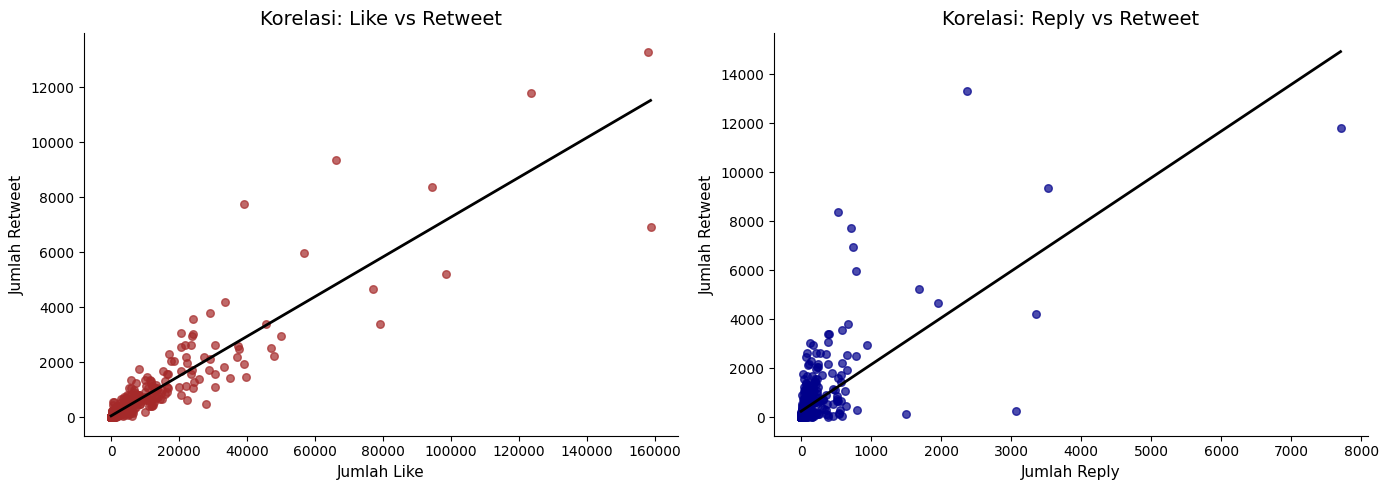

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load dataset engagement metrics
data = pd.read_csv('dataset_engagement_metrics.csv')

# 2. Buat figure dengan 2 subplot (1 baris, 2 kolom)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Grafik 1: Correlation Like vs Retweet ---
sns.regplot(
    data=data,
    x='like',
    y='retweet',
    ci=None,
    color='brown',
    scatter_kws={'s': 30, 'alpha': 0.7},
    line_kws={'color': 'black', 'linewidth': 2},
    ax=axes[0]
)
axes[0].set_title("Korelasi: Like vs Retweet", fontsize=14)
axes[0].set_xlabel("Jumlah Like", fontsize=11)
axes[0].set_ylabel("Jumlah Retweet", fontsize=11)

# --- Grafik 2: Correlation Reply vs Retweet ---
sns.regplot(
    data=data,
    x='reply',
    y='retweet',
    ci=None,
    color='darkblue',
    scatter_kws={'s': 30, 'alpha': 0.7},
    line_kws={'color': 'black', 'linewidth': 2},
    ax=axes[1]
)
axes[1].set_title("Korelasi: Reply vs Retweet", fontsize=14)
axes[1].set_xlabel("Jumlah Reply", fontsize=11)
axes[1].set_ylabel("Jumlah Retweet", fontsize=11)

# Hapus garis tepi atas dan kanan
sns.despine()

plt.tight_layout()
plt.show()

In [ ]:
import joblib
joblib.dump(model, 'model_regresi_likes.pkl')

['model_regresi_likes.pkl']

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Load data (sesuaikan nama file csv milikmu)
# data = pd.read_csv('nama_file_kamu.csv')

# 2. Ambil hanya kolom-kolom numerik yang relevan untuk korelasi
kolom_numerik = [
    'favorite_count',
    'retweet_count',
    'reply_count',
    'quote_count',
    'jumlah_tagar',
    'jumlah_kata'
]

# Filter dataframe hanya untuk kolom numerik yang ada
df_numerik = data[kolom_numerik]

# 3. Hitung matriks korelasi (metode Pearson)
matriks_korelasi = df_numerik.corr(method='pearson')

# 4. Buat Visualisasi Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    matriks_korelasi,
    annot=True,
    cmap='tab10',
    fmt='.2f',
    linewidths=0.5,
    square=True
)

plt.title('Heatmap Korelasi Antar Variabel Numerik Tweet', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

KeyError: "['jumlah_tagar', 'jumlah_kata'] not in index"